In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from random_variate_generator import RandomVariateGenerator
from review_queue import simulate_queue, results_summary
from constants import *


In [2]:
# SEED = 42
# NUM_REVIEWERS = 2
# MEAN_REVIEW_TIME = 10      # minutes

In [3]:
transactions = pd.read_csv("data/transaction_table_flagged.csv", parse_dates=["transaction_time"])
flagged = transactions[transactions["flagged"] == 1]

In [4]:
#start_of_year = pd.Timestamp("2025-01-01")
#arrivals = ((flagged["transaction_time"] - start_of_year).dt.total_seconds() / 60).sort_values().tolist()

times = flagged["transaction_time"]
arrivals = sorted((times.dt.hour * 60 + times.dt.minute + times.dt.second / 60).tolist())

In [5]:
urv = RandomVariateGenerator(QUEUE_SEED)
#arrivals = [i * GAP for i in range(NUM_JOBS)]
review_times = [urv.exponential(rate=1/MEAN_REVIEW_TIME) for _ in arrivals]

In [6]:
#results = simulate_queue([0, 1, 2, 10], [5, 5, 5, 5], num_reviewers=2)
results = simulate_queue(arrivals, review_times, NUM_REVIEWERS)

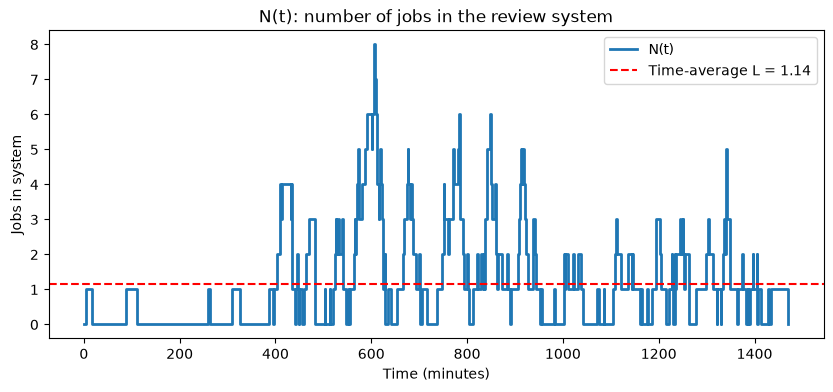

In [7]:
# Each job: arrival (+1), finish (-1); at a tie, the departure is processed first
events = []
for customer in results:
    events.append((customer["arrival"], +1))
    events.append((customer["finish"], -1))
events.sort()

# Running count of jobs in the system
times, counts = [0], [0]
count = 0
for time, change in events:
    count += change
    times.append(time)
    counts.append(count)

# Time-average (area under N(t) / end time)
area = sum(counts[i] * (times[i + 1] - times[i]) for i in range(len(times) - 1))
L = area / times[-1]

plt.figure(figsize=(10, 4))
plt.step(times, counts, where="post", linewidth=2, label="N(t)")
plt.axhline(L, color="red", linestyle="--", label=f"Time-average L = {L:.2f}")
#plt.xlim(arrivals[0] - 30, arrivals[0] + 60)
plt.xlabel("Time (minutes)")
plt.ylabel("Jobs in system")
plt.title("N(t): number of jobs in the review system")
plt.legend()
plt.show()

In [8]:
import pandas as pd

summary = results_summary(results, NUM_REVIEWERS)
summary.update({"seed": QUEUE_SEED, 
                "num_reviewers": NUM_REVIEWERS, 
                "mean_review_time": MEAN_REVIEW_TIME,
                "num_flagged": len(arrivals)})

pd.DataFrame(results).to_csv("data/queue_results.csv", index=False)
pd.DataFrame([summary]).to_csv("data/queue_summary.csv", index=False)

pd.DataFrame([summary])

,avg_wait,W,lambda,utilization,L,Lq,seed,num_reviewers,mean_review_time,num_flagged
0,3.430095,13.153546,0.087035,0.423138,1.144813,0.298537,42,2,10.0,128
